Data Mining — Practice 3
Dataset: Telco Customer Churn  



In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,  accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option('display.max_columns', 30)
df = pd.read_csv("Telco_Customer_Churn.csv")
print(df.shape)
display(df.head())

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Task 1. EDA and Data Preparation
Check dataset, missing values and distributions. Remove customer ID and make a new feature ActiveServices.

In [17]:
df.info()
print("Missing values before cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])
print('Blank TotalCharges:', (df['TotalCharges'].astype(str).str.strip() == '').sum())

df = df.drop(columns=['customerID']).copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection','TechSupport', 'StreamingTV', 'StreamingMovies']
df['ActiveServices'] = df[service_cols].eq('Yes').sum(axis=1)
df['ChurnBinary'] = df['Churn'].map({'No': 0, 'Yes': 1})
print('Shape after cleaning:', df.shape)
print('Missing after cleaning:', df.isna().sum().sum())
display(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'ActiveServices', 'ChurnBinary']].head())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,tenure,MonthlyCharges,TotalCharges,ActiveServices,ChurnBinary
0,1,29.85,29.85,1,0
1,34,56.95,1889.50,2,0
2,2,53.85,108.15,2,1
3,45,42.30,1840.75,3,0
4,2,70.70,151.65,0,1


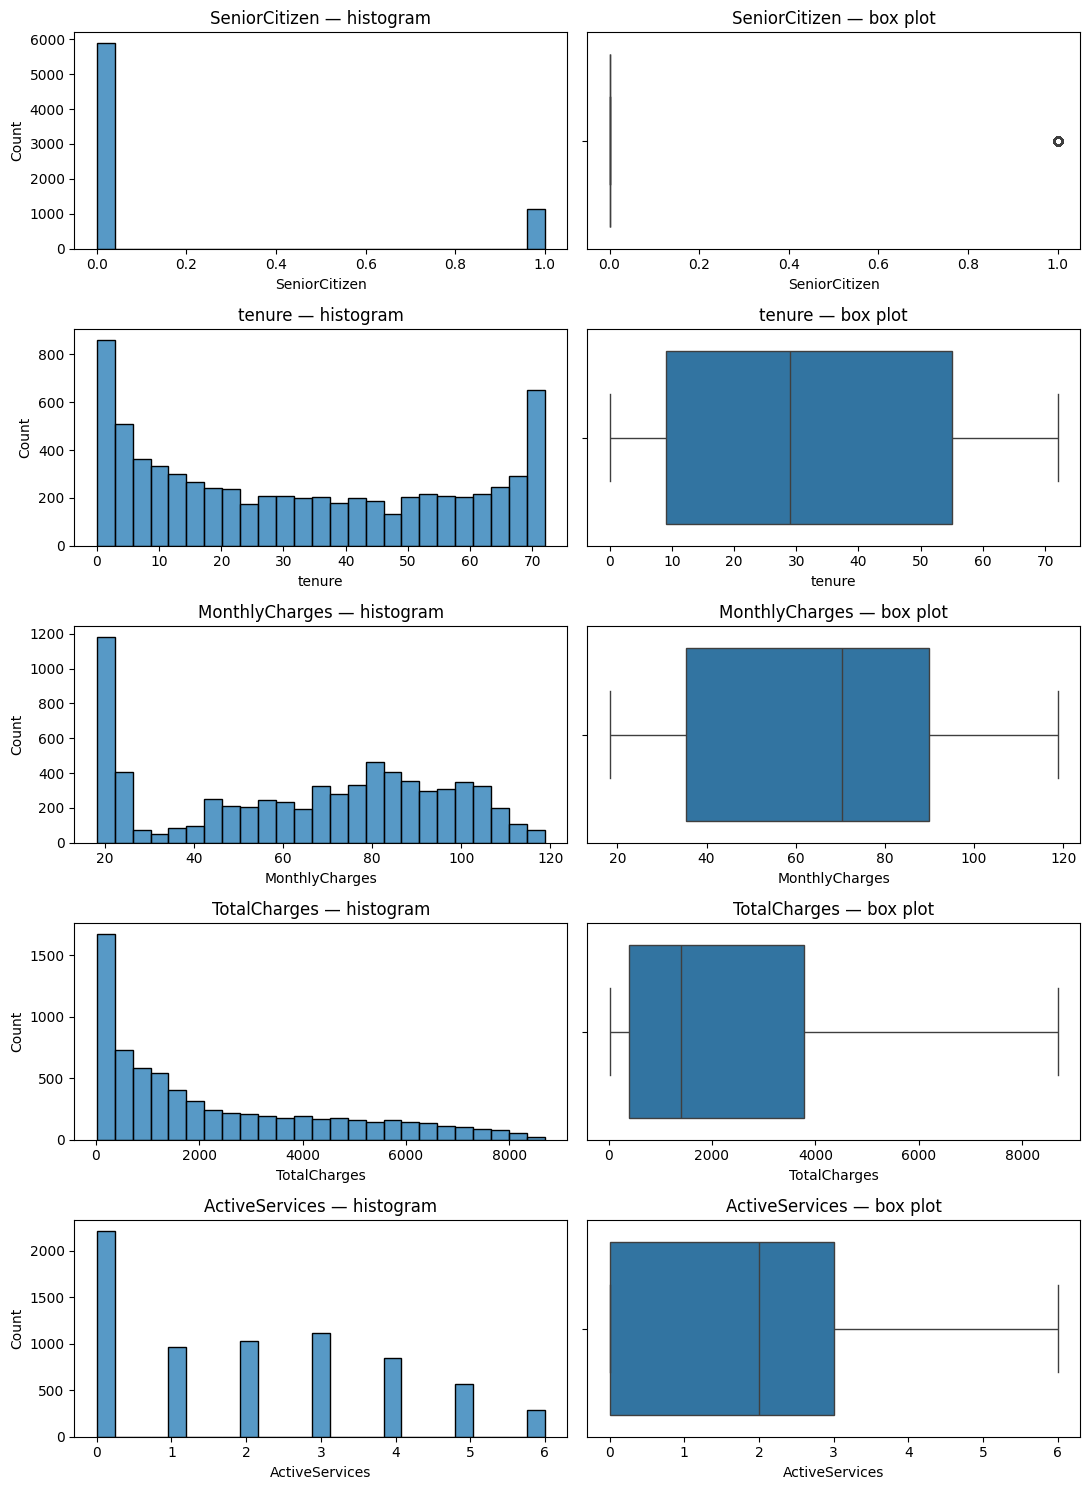

Skew before: 0.9638
Skew after log1p: -0.7445


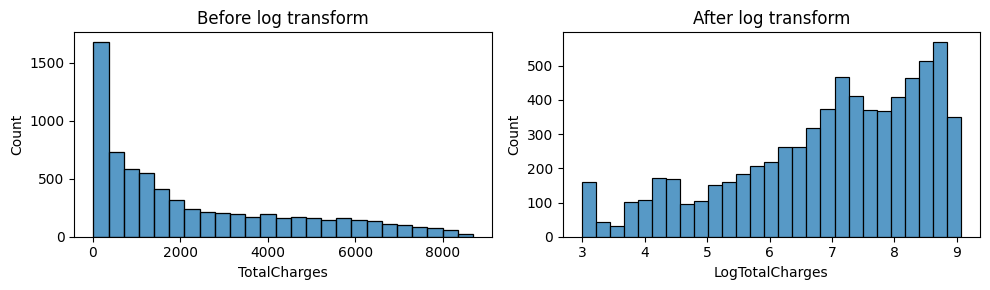

Interpretation: log1p compresses large TotalCharges values. Compare the two skew values above


In [18]:
numeric_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ActiveServices']
fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(11, 15))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=25, ax=axes[i, 0])
    axes[i, 0].set_title(col + ' — histogram')
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(col + ' — box plot')
plt.tight_layout()
plt.show()

print('Skew before:', round(df['TotalCharges'].skew(), 4))
df['LogTotalCharges'] = np.log1p(df['TotalCharges'])
print('Skew after log1p:', round(df['LogTotalCharges'].skew(), 4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(df['TotalCharges'], ax=ax[0]); ax[0].set_title('Before log transform')
sns.histplot(df['LogTotalCharges'], ax=ax[1]); ax[1].set_title('After log transform')
plt.tight_layout(); plt.show()
print("Interpretation: log1p compresses large TotalCharges values. Compare the two skew values above")

Task 2. Regression
Simple Regression uses only tenure. Multiple Regression uses 4 numeric features. The target is log-transformed for training, but metrics are calculated in the original TotalCharges units.

In [19]:
reg_features = ['tenure', 'MonthlyCharges', 'ActiveServices', 'SeniorCitizen']
Xreg_train, Xreg_test, yreg_train, yreg_test = train_test_split(
    df[reg_features], df['LogTotalCharges'], test_size=0.2, random_state=42)

reg_results = []
for name, cols in [('Simple Regression', ['tenure']), ('Multiple Regression', reg_features)]:
    model = LinearRegression()
    model.fit(Xreg_train[cols], yreg_train)
    pred = np.expm1(model.predict(Xreg_test[cols]))
    true = np.expm1(yreg_test)
    reg_results.append({'Model': name, 'R2': r2_score(true, pred),'RMSE': np.sqrt(mean_squared_error(true, pred)),'MAE': mean_absolute_error(true, pred)})
reg_table = pd.DataFrame(reg_results).set_index('Model')
display(reg_table.round(4))
print("Difference (Multiple minus Simple):")
print((reg_table.loc['Multiple Regression'] - reg_table.loc["Simple Regression"]).round(4))
print("Better by RMSE:", reg_table["RMSE"].idxmin(), "and lower RMSE is better")

,R2,RMSE,MAE
Model,,,
Simple Regression,0.4365,1711.6116,1098.1498
Multiple Regression,0.2517,1972.4925,1003.4092


Difference (Multiple minus Simple):
R2       -0.1849
RMSE    260.8809
MAE     -94.7406
dtype: float64
Better by RMSE: Simple Regression and lower RMSE is better


Prepare classification features
Use the same train/test split for all classifiers to make comparison fair. Scaling is fitted only on train data.

In [20]:
classification_features = ['tenure', 'MonthlyCharges', 'TotalCharges','SeniorCitizen', 'ActiveServices']
X = df[classification_features].copy()
X = pd.concat([X, pd.get_dummies(df['Contract'], prefix='Contract', dtype=int)], axis=1)
y = df['ChurnBinary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train.shape, "and  Test:", X_test.shape)
print("Churn rate in train:", round(y_train.mean(), 4))

Train: (5634, 8) and  Test: (1409, 8)
Churn rate in train: 0.2654


Task 3. Classification
Use Decision Tree for the basic classification workflow. Metrics for the positive class (Churn = Yes).

In [21]:
tree_basic = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_basic.fit(X_train, y_train)
pred_basic = tree_basic.predict(X_test)
def get_metrics(actual, predicted):
    return {'Accuracy': accuracy_score(actual, predicted),'Precision': precision_score(actual, predicted, zero_division=0),'Recall': recall_score(actual, predicted, zero_division=0),'F1': f1_score(actual, predicted, zero_division=0)}
metrics_basic = get_metrics(y_test, pred_basic)
display(pd.DataFrame([metrics_basic], index=['Decision Tree']).round(4))
print("Interpretation: accuracy is overall correctness, precision is how many predicted churners actually left, recall is how many churners we found, and F1 balances precision and recall")

,Accuracy,Precision,Recall,F1
Decision Tree,0.7892,0.637,0.4786,0.5466


Interpretation: accuracy is overall correctness, precision is how many predicted churners actually left, recall is how many churners we found, and F1 balances precision and recall


Task 4. K-Means Clustering
Scale numeric features, try k = 2, 3, 4. Plot 2 original features; color = cluster. Compare each cluster with actual Churn percentage.

k=2, inertia=13129.53
Churn     No    Yes
row_0              
0      0.681  0.319
1      0.828  0.172
k=3, inertia=9021.30
Churn     No    Yes
row_0              
0      0.853  0.147
1      0.544  0.456
2      0.855  0.145
k=4, inertia=7076.34
Churn     No    Yes
row_0              
0      0.957  0.043
1      0.855  0.145
2      0.678  0.322
3      0.573  0.427


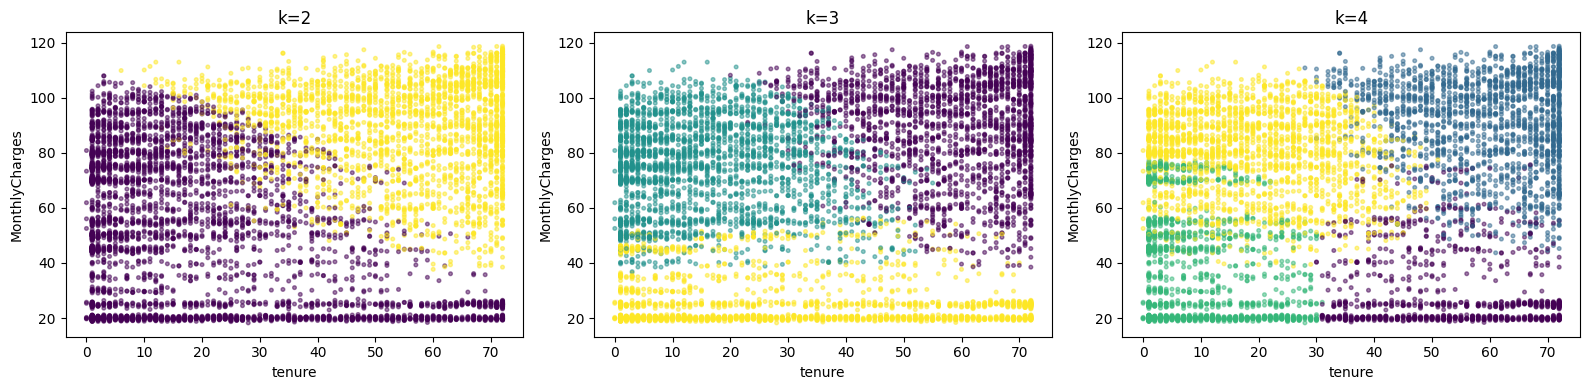

Interpretation: inspect whether the percentages of Churn=Yes are different between clusters. Clusters are formed without using Churn labels


In [22]:
cluster_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'ActiveServices']
cluster_scaler = StandardScaler()
Xcluster = cluster_scaler.fit_transform(df[cluster_features])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k in zip(axes, [2, 3, 4]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(Xcluster)
    ax.scatter(df['tenure'], df['MonthlyCharges'], c=labels, cmap='viridis', s=7, alpha=0.5)
    ax.set(title=f'k={k}', xlabel='tenure', ylabel='MonthlyCharges')
    print(f'k={k}, inertia={km.inertia_:.2f}')
    print(pd.crosstab(labels, df['Churn'], normalize='index').round(3))
plt.tight_layout(); plt.show()
print("Interpretation: inspect whether the percentages of Churn=Yes are different between clusters. Clusters are formed without using Churn labels")

purple - low tenure low MonthlyCharges, yellow - high tenure, high MonthlyCharges

yellow - low MonthlyCharges, blue - low tenure, mid or high MonthlyCharges purple - high tenure, mid or high MonthlyCharges

yellow - low tenure, high payments, blue - high tenure, high payments, green - low tenure, low and mid payment
purple- - high tenure, low or mid payment

Task 5. Logistic Regression
Show 5 predicted probabilities and apply threshold = 0.5. AUC-ROC measures ranking quality across thresholds.

In [23]:
log_model = LogisticRegression(max_iter=2000, random_state=42)
log_model.fit(X_train_s, y_train)
proba = log_model.predict_proba(X_test_s)[:, 1]
pred_log = (proba >= 0.5).astype(int)
result5 = pd.DataFrame({'Actual': y_test.iloc[:5].to_numpy(),'P(Churn=Yes)': proba[:5].round(4),'Predicted (0.5)': pred_log[:5]}, index=X_test.index[:5])
display(result5)
print("AUC-ROC:", round(roc_auc_score(y_test, proba), 4))
print("Interpretation: when P >= 0.5, the predicted class is 1")

,Actual,P(Churn=Yes),Predicted (0.5)
437,0,0.0551,0
2280,0,0.7469,1
2235,0,0.0987,0
4460,0,0.4675,0
3761,0,0.0165,0


AUC-ROC: 0.8327
Interpretation: when P >= 0.5, the predicted class is 1


Task 6. SVM
Compare linear and rbf kernels on the same scaled dataset. Support vectors are points closest to / important for the decision boundary.

In [24]:
svm_results = []
for kernel in ['linear', 'rbf']:
    clf = SVC(kernel=kernel, random_state=42)
    clf.fit(X_train_s, y_train)
    svm_results.append({'Kernel': kernel,'Support vectors': clf.support_vectors_.shape[0],'Accuracy': accuracy_score(y_test, clf.predict(X_test_s))})
svm_table = pd.DataFrame(svm_results).set_index('Kernel')
display(svm_table.round(4))
print("Better kernel:", svm_table['Accuracy'].idxmax())
print("Interpretation: linear uses a straight boundary in feature space; RBF can model nonlinear boundaries")

,Support vectors,Accuracy
Kernel,,
linear,2716,0.7821
rbf,2553,0.7949


Better kernel: rbf
Interpretation: linear uses a straight boundary in feature space; RBF can model nonlinear boundaries


Task 7. KNN + Elbow Method
Use Euclidean distance. Choose k from a validation set, then report final test accuracy. This keeps the test set unseen while choosing k.

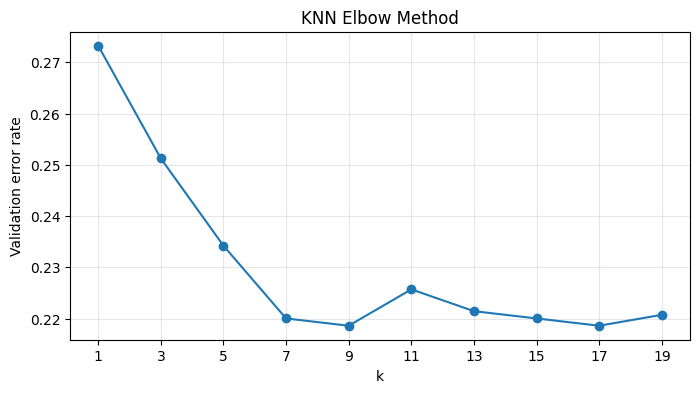

Selected k: 9
Validation error: 0.2186
Final test accuracy: 0.7885
Interpretation: the curve shows whether adding neighbors reduces error. Selected k minimizes validation error, not necessarily the exact visual elbow


In [25]:
X_ktrain, X_val, y_ktrain, y_val = train_test_split(
    X_train_s, y_train, test_size=0.25, stratify=y_train, random_state=42)
ks = list(range(1, 21, 2))
errors = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_ktrain, y_ktrain)
    errors.append(1 - accuracy_score(y_val, knn.predict(X_val)))
plt.figure(figsize=(8, 4))
plt.plot(ks, errors, marker='o')
plt.xticks(ks); plt.xlabel('k'); plt.ylabel('Validation error rate')
plt.title('KNN Elbow Method'); plt.grid(alpha=0.3); plt.show()
best_k = ks[int(np.argmin(errors))]
knn_final = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_final.fit(X_train_s, y_train)
print("Selected k:", best_k)
print("Validation error:", round(min(errors), 4))
print("Final test accuracy:", round(accuracy_score(y_test, knn_final.predict(X_test_s)), 4))
print("Interpretation: the curve shows whether adding neighbors reduces error. Selected k minimizes validation error, not necessarily the exact visual elbow")

Task 8. Decision Tree + Entropy and Information Gain
Train a tree with criterion="entropy". Extract the actual root split from sklearn and manually calculate the entropy and information gain for that exact split.

Root feature: Contract_Month-to-month
Root threshold: 0.5
Parent entropy: 0.834717
Left entropy: 0.35366 | samples: 2532
Right entropy: 0.984766 | samples: 3102
Information Gain (manual): 0.13358
Information Gain (sklearn): 0.594842
Test accuracy: 0.7864


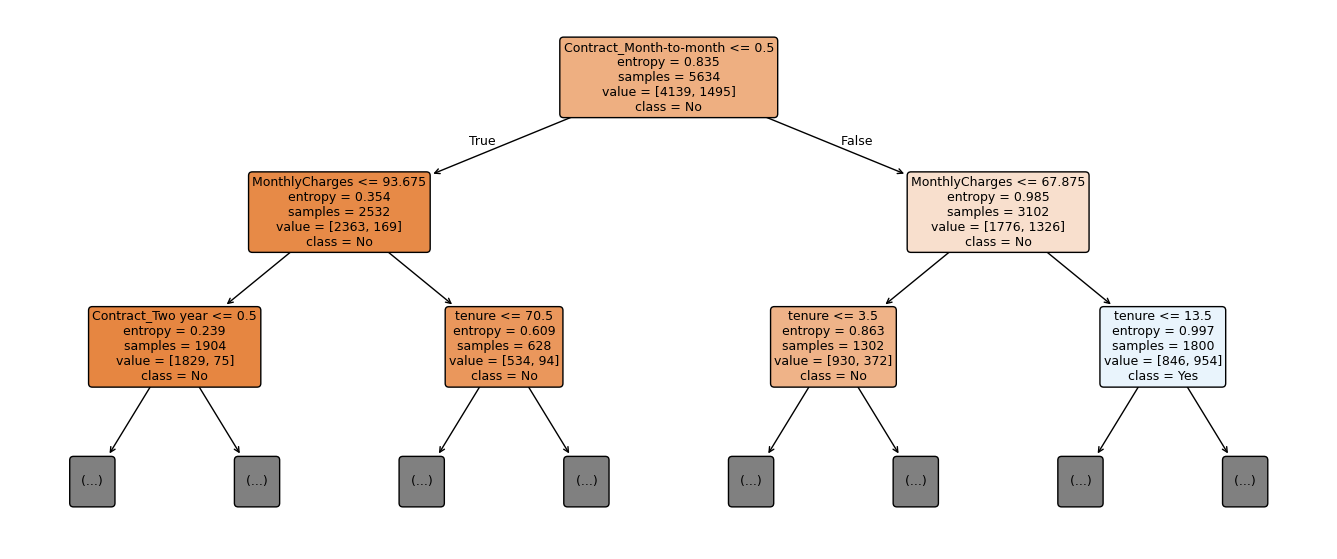

Interpretation: sklearn selected the root split that maximizes Information Gain among candidate splits. The two IG numbers above should match


In [26]:
tree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
tree.fit(X_train, y_train)
root_id = 0
root_feature_id = tree.tree_.feature[root_id]
root_feature = X_train.columns[root_feature_id]
root_threshold = tree.tree_.threshold[root_id]

left_mask = X_train.iloc[:, root_feature_id].to_numpy() <= root_threshold
left_y = y_train.to_numpy()[left_mask]
right_y = y_train.to_numpy()[~left_mask]

def entropy(values):
    probs = pd.Series(values).value_counts(normalize=True).to_numpy()
    return float(-np.sum(probs * np.log2(probs)))

h_before = entropy(y_train)
h_left = entropy(left_y)
h_right = entropy(right_y)
weighted_entropy = (len(left_y) * h_left + len(right_y) * h_right) / len(y_train)
information_gain = h_before - weighted_entropy

print('Root feature:', root_feature)
print('Root threshold:', round(root_threshold, 4))
print('Parent entropy:', round(h_before, 6))
print('Left entropy:', round(h_left, 6), '| samples:', len(left_y))
print('Right entropy:', round(h_right, 6), '| samples:', len(right_y))
print('Information Gain (manual):', round(information_gain, 6))
print('Information Gain (sklearn):', round(tree.tree_.impurity[0] - (tree.tree_.n_node_samples[1] * tree.tree_.impurity[1] +tree.tree_.n_node_samples[2] * tree.tree_.impurity[2]) / tree.tree_.n_node_samples[0], 6))
print('Test accuracy:', round(accuracy_score(y_test, tree.predict(X_test)), 4))
plt.figure(figsize=(17, 7))
plot_tree(tree, feature_names=X_train.columns, class_names=['No', 'Yes'],
          filled=True, rounded=True, max_depth=2, fontsize=9)
plt.show()
print("Interpretation: sklearn selected the root split that maximizes Information Gain among candidate splits. The two IG numbers above should match")

Final conclusion

Regression: Compare R² (higher is better), RMSE and MAE (lower is better) from Task 2
Classification: Decision Tree metrics are reported in Task 3; Logistic Regression adds probabilities and AUC in Task 5
Clustering: K-Means does not know the Churn labels. Compare the Churn distribution between clusters
SVM Compare linear and RBF accuracy and support vector counts
KNN Choose k based on validation, then evaluate on the independent test set
Decision Tree: The root split was checked by manual entropy / Information Gain calculation

